# Movie Recommendation Engine (Content-Based Filtering)

Recommends movies similar to a given movie using the **TMDB 5000 Movies** dataset.

**Approach:** combine genres, keywords, overview, cast and director into a single text field (`tags`),
convert it to numbers with **TF-IDF**, and rank movies by **cosine similarity**.

**Pipeline**
1. Load and inspect the data
2. Handle missing values and duplicates
3. Feature engineering (`tags`)
4. TF-IDF vectorization and cosine similarity
5. Recommendation function
6. Exploratory data analysis
7. Save model artifacts for the Streamlit app

## 1. Load and Inspect the Data

In [70]:
import re
import os
import difflib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
df=pd.read_csv("movies.csv")

In [71]:
print(df.shape)

(4803, 24)


In [72]:
print(df.head())

   index     budget                                    genres  \
0      0  237000000  Action Adventure Fantasy Science Fiction   
1      1  300000000                  Adventure Fantasy Action   
2      2  245000000                    Action Adventure Crime   
3      3  250000000               Action Crime Drama Thriller   
4      4  260000000          Action Adventure Science Fiction   

                                       homepage      id  \
0                   http://www.avatarmovie.com/   19995   
1  http://disney.go.com/disneypictures/pirates/     285   
2   http://www.sonypictures.com/movies/spectre/  206647   
3            http://www.thedarkknightrises.com/   49026   
4          http://movies.disney.com/john-carter   49529   

                                            keywords original_language  \
0  culture clash future space war space colony so...                en   
1  ocean drug abuse exotic island east india trad...                en   
2         spy based on novel sec

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 4803 non-null   int64  
 1   budget                4803 non-null   int64  
 2   genres                4775 non-null   object 
 3   homepage              1712 non-null   object 
 4   id                    4803 non-null   int64  
 5   keywords              4391 non-null   object 
 6   original_language     4803 non-null   object 
 7   original_title        4803 non-null   object 
 8   overview              4800 non-null   object 
 9   popularity            4803 non-null   float64
 10  production_companies  4803 non-null   object 
 11  production_countries  4803 non-null   object 
 12  release_date          4802 non-null   object 
 13  revenue               4803 non-null   int64  
 14  runtime               4801 non-null   float64
 15  spoken_languages     

In [74]:
print(df.isnull().sum())
print(df.isnull())
#df.isnull().sum()

index                      0
budget                     0
genres                    28
homepage                3091
id                         0
keywords                 412
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
cast                      43
crew                       0
director                  30
dtype: int64
      index  budget  genres  homepage     id  keywords  original_language  \
0     False   False   False     False  False     False              False   
1     False   False   False     False  False     False              False   
2     False   False   False     False  False     False      

In [75]:
# Missing values per column (count and percentage)
missing = df.isnull().sum()
pd.DataFrame({
    "missing": missing,
    "percent": (missing / len(df) * 100).round(2)
}).sort_values("missing", ascending=False).head(10)

,missing,percent
homepage,3091,64.36
tagline,844,17.57
keywords,412,8.58
cast,43,0.90
director,30,0.62
genres,28,0.58
overview,3,0.06
runtime,2,0.04
release_date,1,0.02
popularity,0,0.00


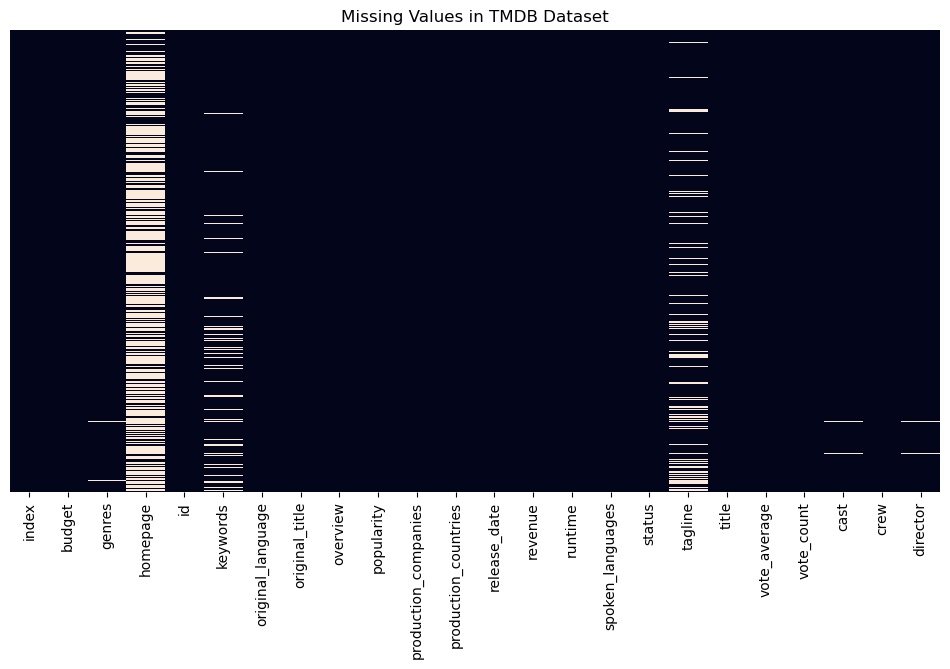

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in TMDB Dataset")
plt.show()

## 2. Data Cleaning

- **Text features** (`genres`, `keywords`, `overview`, `cast`, `director`): missing values are filled with an empty string so they can be concatenated safely.
- **`runtime`**: only 2 missing values, filled with the median.
- **`release_date`**: only 1 missing value, that row is dropped.
- **Duplicate titles**: the recommender looks movies up by title, so each title must be unique. For duplicates, the entry with the most votes is kept.

In [77]:
df['runtime'] = df['runtime'].fillna(df['runtime'].median())
df = df.dropna(subset=['release_date'])

df.isnull().sum()

index                      0
budget                     0
genres                    27
homepage                3090
id                         0
keywords                 411
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               0
revenue                    0
runtime                    0
spoken_languages           0
status                     0
tagline                  843
title                      0
vote_average               0
vote_count                 0
cast                      42
crew                       0
director                  29
dtype: int64

In [78]:
df[df.isnull().any(axis=1)][['title', 'genres', 'keywords', 'overview', 'cast', 'director', 'runtime', 'release_date']]

,title,genres,keywords,overview,cast,director,runtime,release_date
10,Superman Returns,Adventure Fantasy Action Science Fiction,saving the world dc comics invulnerability seq...,Superman returns to discover his 5-year absenc...,Brandon Routh Kevin Spacey Kate Bosworth James...,Bryan Singer,154.0,2006-06-28
15,The Chronicles of Narnia: Prince Caspian,Adventure Family Fantasy,based on novel fictional place brother sister ...,One year after their incredible adventures in ...,Ben Barnes William Moseley Anna Popplewell Ska...,Andrew Adamson,150.0,2008-05-15
24,King Kong,Adventure Drama Action,film business screenplay show business film ma...,"In 1933 New York, an overly ambitious movie pr...",Naomi Watts Jack Black Adrien Brody Thomas Kre...,Peter Jackson,187.0,2005-12-14
27,Battleship,Thriller Action Adventure Science Fiction,fight u.s. navy mind reading hong kong soccer,"When mankind beams a radio signal into space, ...",Taylor Kitsch Alexander Skarsg\u00e5rd Rihanna...,Peter Berg,131.0,2012-04-11
33,X-Men: The Last Stand,Adventure Action Science Fiction Thriller,mutant marvel comic based on comic book superh...,"When a cure is found to treat mutations, lines...",Hugh Jackman Halle Berry Ian McKellen Patrick ...,Brett Ratner,104.0,2006-05-24
...,...,...,...,...,...,...,...,...
4798,El Mariachi,Action Crime Thriller,united states\u2013mexico barrier legs arms pa...,El Mariachi just wants to play his guitar and ...,Carlos Gallardo Jaime de Hoyos Peter Marquardt...,Robert Rodriguez,81.0,1992-09-04
4799,Newlyweds,Comedy Romance,NaN,A newlywed couple's honeymoon is upended by th...,Edward Burns Kerry Bish\u00e9 Marsha Dietlein ...,Edward Burns,85.0,2011-12-26
4800,"Signed, Sealed, Delivered",Comedy Drama Romance TV Movie,date love at first sight narration investigati...,"""Signed, Sealed, Delivered"" introduces a dedic...",Eric Mabius Kristin Booth Crystal Lowe Geoff G...,Scott Smith,120.0,2013-10-13
4801,Shanghai Calling,NaN,NaN,When ambitious New York attorney Sam is sent t...,Daniel Henney Eliza Coupe Bill Paxton Alan Ruc...,Daniel Hsia,98.0,2012-05-03


In [79]:
print(df.columns.tolist())

['index', 'budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'cast', 'crew', 'director']


In [80]:
df.duplicated().sum()

np.int64(0)

In [81]:
df.describe()

,index,budget,id,popularity,revenue,runtime,vote_average,vote_count
count,4802.000000,4.802000e+03,4802.000000,4802.000000,4.802000e+03,4802.000000,4802.000000,4802.000000
mean,2400.551853,2.905109e+07,57098.234902,21.496776,8.227777e+07,106.896501,6.093440,690.361724
std,1386.447506,4.072447e+07,88581.302370,31.818451,1.628697e+08,22.557033,1.191496,1234.674268
min,0.000000,0.000000e+00,5.000000,0.000372,0.000000e+00,0.000000,0.000000,0.000000
25%,1200.250000,8.000000e+05,9013.750000,4.671734,0.000000e+00,94.000000,5.600000,54.000000
50%,2400.500000,1.500000e+07,14626.500000,12.924931,1.917498e+07,103.000000,6.200000,235.500000
75%,3600.750000,4.000000e+07,58589.750000,28.332017,9.291920e+07,117.750000,6.800000,737.000000
max,4802.000000,3.800000e+08,459488.000000,875.581305,2.787965e+09,338.000000,10.000000,13752.000000


### primarily use these five columns:

In [82]:
features = [
    'genres',
    'keywords',
    'overview',
    'cast',
    'director'
]

2 Fill missing values

In [83]:
df[features] = df[features].fillna('')

df[features].isnull().sum()

genres      0
keywords    0
overview    0
cast        0
director    0
dtype: int64

In [84]:
df['runtime'] = df['runtime'].fillna(df['runtime'].median())
df = df.dropna(subset=['release_date'])

df.isnull().sum()

index                      0
budget                     0
genres                     0
homepage                3090
id                         0
keywords                   0
original_language          0
original_title             0
overview                   0
popularity                 0
production_companies       0
production_countries       0
release_date               0
revenue                    0
runtime                    0
spoken_languages           0
status                     0
tagline                  843
title                      0
vote_average               0
vote_count                 0
cast                       0
crew                       0
director                   0
dtype: int64

### Check our dataset again

In [85]:
print("Dataset shape:", df.shape)

print("\nMissing values in selected features:")
print(df[features].isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Dataset shape: (4802, 24)

Missing values in selected features:
genres      0
keywords    0
overview    0
cast        0
director    0
dtype: int64

Duplicate records: 0


## 3. Feature Engineering

Steps applied before building the `tags` column:

1. **Fix unicode escapes.** The dataset stores some characters as literal text (for example `Cuar\u00f3n`), which would create wrong tokens. They are converted back to real characters.
2. **Merge multi-word genres.** `Science Fiction` becomes `ScienceFiction` so it stays a single token.
3. **Merge director names.** `James Cameron` becomes `JamesCameron`, so two directors who share a first name are not treated as similar.
4. **Weighting.** Genres are repeated 2x and the director 3x so they influence similarity more than the long overview text.

In [86]:
print(df['genres'].str.split().explode().value_counts().head(20))

genres
Drama          2297
Comedy         1722
Thriller       1259
Action         1153
Romance         890
Adventure       790
Crime           696
Fiction         530
Science         530
Horror          519
Family          510
Fantasy         418
Mystery         347
Animation       234
History         197
Music           183
War             142
Documentary     110
Western          80
Foreign          34
Name: count, dtype: int64


#### two different techniques :
- Imputation: Missing value ko suitable value se fill karna.
- Deletion: Missing value wali row ya column remove karna.

In [87]:
df['runtime'] = df['runtime'].fillna(df['runtime'].median())
df = df.dropna(subset=['release_date'])

df.isnull().sum()

index                      0
budget                     0
genres                     0
homepage                3090
id                         0
keywords                   0
original_language          0
original_title             0
overview                   0
popularity                 0
production_companies       0
production_countries       0
release_date               0
revenue                    0
runtime                    0
spoken_languages           0
status                     0
tagline                  843
title                      0
vote_average               0
vote_count                 0
cast                       0
crew                       0
director                   0
dtype: int64

In [88]:
df['tags'] = (
    df['genres'] + ' ' +
    df['keywords'] + ' ' +
    df['overview'] + ' ' +
    df['cast'] + ' ' +
    df['director']
)

* df['tags'] — DataFrame mein ek naya column create karega.
* + — different text values ko combine karega.
* ' ' — har column ke beech space add karega, taaki words chipke nahi.

#### First movie ke tags separately check karne ke liye:

### Cell 1: Genres aur director clean karna

In [89]:
df['genres_clean'] = (
    df['genres']
    .str.replace('Science Fiction', 'ScienceFiction')
    .str.replace('TV Movie', 'TVMovie')
)
df['director_clean'] = df['director'].str.replace(' ', '', regex=False)

df[['genres', 'genres_clean', 'director', 'director_clean']].head(3)

,genres,genres_clean,director,director_clean
0,Action Adventure Fantasy Science Fiction,Action Adventure Fantasy ScienceFiction,James Cameron,JamesCameron
1,Adventure Fantasy Action,Adventure Fantasy Action,Gore Verbinski,GoreVerbinski
2,Action Adventure Crime,Action Adventure Crime,Sam Mendes,SamMendes


In [90]:
df['tags'] = (
    df['genres_clean'] + ' ' +
    df['keywords'] + ' ' +
    df['overview'] + ' ' +
    df['cast'] + ' ' +
    df['director_clean']
).str.lower()

print(df['tags'].iloc[0])

action adventure fantasy sciencefiction culture clash future space war space colony society in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. sam worthington zoe saldana sigourney weaver stephen lang michelle rodriguez jamescameron


In [91]:
print(df['tags'].iloc[0])

action adventure fantasy sciencefiction culture clash future space war space colony society in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. sam worthington zoe saldana sigourney weaver stephen lang michelle rodriguez jamescameron


In [92]:
print("Dataset shape:", df.shape)
print("Total columns:", len(df.columns))
print("Tags column exists:", 'tags' in df.columns)

Dataset shape: (4802, 27)
Total columns: 27
Tags column exists: True


1. Text Preprocessing kya hoti hai?
Text preprocessing ka matlab hai raw text ko clean aur standard format mein convert karna, taaki Machine Learning model usse better understand kar sake.

Action Adventure Science Fiction
ACTION ADVENTURE SCIENCE FICTION
action adventure science fiction

Insaan ke liye ye same words hain, lekin computer inhe different text forms samajh sakta hai.

In [93]:
df['tags'] = df['tags'].apply(lambda x: x.lower())

Line-by-line explanation:
- df['tags'] — tags column select karta hai.
- .apply() — column ke har element par function apply karta hai.
- lambda x: — har row ke text ko x naam se represent karta hai.
- x.lower() — saare uppercase letters ko lowercase mein convert karta hai.

In [94]:
print(df['tags'].iloc[0])

action adventure fantasy sciencefiction culture clash future space war space colony society in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. sam worthington zoe saldana sigourney weaver stephen lang michelle rodriguez jamescameron


In [95]:
print(df[['title', 'tags']].head(3))

                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   

                                                tags  
0  action adventure fantasy sciencefiction cultur...  
1  adventure fantasy action ocean drug abuse exot...  
2  action adventure crime spy based on novel secr...  


In [96]:
print(df['tags'].iloc[0])
print()
print(df['tags'].iloc[1])

action adventure fantasy sciencefiction culture clash future space war space colony society in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. sam worthington zoe saldana sigourney weaver stephen lang michelle rodriguez jamescameron

adventure fantasy action ocean drug abuse exotic island east india trading company love of one's life captain barbossa, long believed to be dead, has come back to life and is headed to the edge of the earth with will turner and elizabeth swann. but nothing is quite as it seems. johnny depp orlando bloom keira knightley stellan skarsg\u00e5rd chow yun-fat goreverbinski


In [97]:
df = df.reset_index(drop=True)
print("Duplicate titles:", df['title'].duplicated().sum())

Duplicate titles: 3


In [98]:
print("empty tags:", (df['tags'].str.strip() == '').sum())

empty tags: 0


In [99]:
duplicate_movies = df[
    df['title'].duplicated(keep=False)
]

duplicate_movies = duplicate_movies.sort_values(
    ['title', 'vote_count'],
    ascending=[True, False]
)

print("Duplicate title records:", len(duplicate_movies))

print(
    duplicate_movies[
        ['title', 'release_date', 'vote_count', 'id']
    ]
)

Duplicate title records: 6
                title release_date  vote_count     id
1359           Batman   1989-06-23        2096    268
4267           Batman   1966-07-30         203   2661
3693  Out of the Blue   2006-10-12          18  10844
3647  Out of the Blue   1980-05-01          17  39269
972          The Host   2013-03-22        1817  72710
2877         The Host   2006-07-27         537   1255


### final checks

In [100]:
print("Dataset shape:", df.shape)

print("Duplicate IDs:", df['id'].duplicated().sum())

print("Duplicate complete rows:", df.duplicated().sum())

print("Duplicate titles:", df['title'].duplicated().sum())

Dataset shape: (4802, 27)
Duplicate IDs: 0


Duplicate complete rows: 0
Duplicate titles: 3


In [101]:
print("Total columns:", len(df.columns))

print(df.columns.tolist())

Total columns: 27
['index', 'budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'cast', 'crew', 'director', 'tags', 'genres_clean', 'director_clean']


In [102]:
print(df[['genres', 'genres_clean']].head(3))

print(df[['director', 'director_clean']].head(3))

                                     genres  \
0  Action Adventure Fantasy Science Fiction   
1                  Adventure Fantasy Action   
2                    Action Adventure Crime   

                              genres_clean  
0  Action Adventure Fantasy ScienceFiction  
1                 Adventure Fantasy Action  
2                   Action Adventure Crime  
         director director_clean
0   James Cameron   JamesCameron
1  Gore Verbinski  GoreVerbinski
2      Sam Mendes      SamMendes


In [103]:
print(df[['genres_clean', 'director_clean']].isnull().sum())

genres_clean      0
director_clean    0
dtype: int64


PorterStemmer NLTK library ka stemming algorithm hai.

In [104]:
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()

In [105]:
df['tags'] = (
    df['genres_clean'] + ' ' +
    df['keywords'] + ' ' +
    df['overview'] + ' ' +
    df['cast'] + ' ' +
    df['director_clean']
)

In [106]:
df['tags'] = df['tags'].apply(lambda x: x.lower())
print(df['tags'].iloc[0])

action adventure fantasy sciencefiction culture clash future space war space colony society in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. sam worthington zoe saldana sigourney weaver stephen lang michelle rodriguez jamescameron


In [107]:
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()
words = ['playing', 'played', 'plays', 'loving', 'studies']

for word in words:
    print(word, "---->", ps.stem(word))

playing ----> play
played ----> play
plays ----> play
loving ----> love
studies ----> studi


In [108]:
def stem(text):
    words = text.split()

    stemmed_words = []

    for word in words:
        stemmed_words.append(ps.stem(word))

    return " ".join(stemmed_words)

df['tags'] = df['tags'].apply(stem)

In [109]:
print(df['tags'].iloc[0])

action adventur fantasi sciencefict cultur clash futur space war space coloni societi in the 22nd century, a parapleg marin is dispatch to the moon pandora on a uniqu mission, but becom torn between follow order and protect an alien civilization. sam worthington zoe saldana sigourney weaver stephen lang michel rodriguez jamescameron


In [110]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. TF-IDF
tfidf = TfidfVectorizer(stop_words='english', max_features=5000)
tfidf_matrix = tfidf.fit_transform(df['tags'])
print("TF-IDF shape:", tfidf_matrix.shape)

# 2. Cosine similarity
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)
print("Similarity shape:", cosine_sim.shape)

# 3. Title -> index
indices = pd.Series(df.index, index=df['title'].str.lower()).drop_duplicates()

def quick_recs(tags_col, title, n=5):
    tf = TfidfVectorizer(stop_words='english', max_features=5000)
    m = tf.fit_transform(df[tags_col])
    i = df[df['title'] == title].index[0]
    sims = cosine_similarity(m[i], m).flatten()
    top = sims.argsort()[::-1][1:n+1]
    return df['title'].iloc[top].tolist()

df['tags_raw'] = (df['genres'] + ' ' + df['keywords'] + ' ' + df['overview'] + ' ' + df['cast'] + ' ' + df['director']).str.lower()

print("Space hata ke :", quick_recs('tags', 'Avatar'))
print("Space ke saath:", quick_recs('tags_raw', 'Avatar'))

TF-IDF shape: (4802, 5000)
Similarity shape: (4802, 4802)
Space hata ke : ['Aliens', 'Lifeforce', 'Guardians of the Galaxy', 'Star Trek Beyond', 'Cargo']
Space ke saath: ['Lifeforce', 'Moonraker', 'Lost in Space', 'Aliens', 'Guardians of the Galaxy']


In [111]:
def recommend(title, n=10):
    key = title.lower().strip()

    if key not in indices:
        matches = df[df['title'].str.lower().str.contains(key, regex=False)]['title'].head(5).tolist()
        print(f"'{title}' nahi mili.")
        if matches:
            print("Shayad ye chahiye the:", matches)
        return None

    idx = indices[key]
    scores = list(enumerate(cosine_sim[idx]))
    scores = sorted(scores, key=lambda x: x[1], reverse=True)[1:n+1]

    movie_idx = [i[0] for i in scores]
    result = df.loc[movie_idx, ['title', 'genres', 'director', 'vote_average']].copy()
    result['similarity'] = [round(i[1], 3) for i in scores]
    return result.reset_index(drop=True)

In [112]:
print(df.shape)
print('tags' in df.columns)


(4802, 28)
True


In [113]:
print("before:", df.shape, "| Duplicate titles:", df['title'].duplicated().sum())

df = (
    df.sort_values('vote_count', ascending=False)
      .drop_duplicates(subset='title', keep='first')
      .sort_index()
      .reset_index(drop=True)
)

print("after:", df.shape, "| Duplicate titles:", df['title'].duplicated().sum())


before: (4802, 28) | Duplicate titles: 3
after: (4799, 28) | Duplicate titles: 0


In [114]:

# 1. TF-IDF
tfidf = TfidfVectorizer(stop_words='english', max_features=5000)
tfidf_matrix = tfidf.fit_transform(df['tags'])
print("TF-IDF shape:", tfidf_matrix.shape)

# 2. Cosine similarity
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)
print("Similarity shape:", cosine_sim.shape)

# 3. Title -> index
indices = pd.Series(df.index, index=df['title'].str.lower()).drop_duplicates()

TF-IDF shape: (4799, 5000)
Similarity shape: (4799, 4799)


In [115]:
def recommend(title, n=10):
    key = title.lower().strip()

    if key not in indices:
        matches = df[df['title'].str.lower().str.contains(key, regex=False)]['title'].head(5).tolist()
        print(f"'{title}' nahi mili.")
        if matches:
            print("Shayad ye chahiye the:", matches)
        return None

    idx = indices[key]
    scores = list(enumerate(cosine_sim[idx]))
    scores = sorted(scores, key=lambda x: x[1], reverse=True)[1:n+1]

    movie_idx = [i[0] for i in scores]
    result = df.loc[movie_idx, ['title', 'genres', 'director', 'vote_average']].copy()
    result['similarity'] = [round(i[1], 3) for i in scores]
    return result.reset_index(drop=True)

In [116]:
print(recommend('Avatar'))
print(recommend('The Dark Knight'))
print(recommend('Toy Story'))
print(recommend('avtar'))

                     title                                     genres  \
0                   Aliens     Horror Action Thriller Science Fiction   
1  Guardians of the Galaxy           Action Science Fiction Adventure   
2                Lifeforce    Fantasy Horror Science Fiction Thriller   
3         Star Trek Beyond           Action Adventure Science Fiction   
4                    Cargo           Thriller Mystery Science Fiction   
5           Silent Running            Adventure Drama Science Fiction   
6                    Alien     Horror Action Thriller Science Fiction   
7                  Gravity             Science Fiction Thriller Drama   
8                Moonraker  Action Adventure Thriller Science Fiction   
9             Space Chimps                           Animation Family   

              director  vote_average  similarity  
0        James Cameron           7.7       0.259  
1           James Gunn           7.9       0.211  
2          Tobe Hooper           6.2       

In [117]:
def fix_unicode(text):
    """Convert literal escape sequences such as \\u00f3 into real characters."""
    return re.sub(r"\\u([0-9a-fA-F]{4})", lambda m: chr(int(m.group(1), 16)), text)


for col in ["cast", "director", "keywords", "overview"]:
    df[col] = df[col].apply(fix_unicode)

df["genres_clean"] = (
    df["genres"]
    .str.replace("Science Fiction", "ScienceFiction")
    .str.replace("TV Movie", "TVMovie")
)
df["director_clean"] = df["director"].str.replace(" ", "", regex=False)
df["release_year"] = pd.to_datetime(df["release_date"]).dt.year.astype(int)

df[["title", "genres", "genres_clean", "director", "director_clean"]].head(3)

,title,genres,genres_clean,director,director_clean
0,Avatar,Action Adventure Fantasy Science Fiction,Action Adventure Fantasy ScienceFiction,James Cameron,JamesCameron
1,Pirates of the Caribbean: At World's End,Adventure Fantasy Action,Adventure Fantasy Action,Gore Verbinski,GoreVerbinski
2,Spectre,Action Adventure Crime,Action Adventure Crime,Sam Mendes,SamMendes


In [118]:
df["tags"] = (
    (df["genres_clean"] + " ") * 2 +      # genres weighted 2x
    df["keywords"] + " " +
    df["overview"] + " " +
    df["cast"] + " " +
    (df["director_clean"] + " ") * 3      # director weighted 3x
).str.lower()

print("Empty tags:", (df["tags"].str.strip() == "").sum())
print()
print(df["tags"].iloc[0])

Empty tags: 0

action adventure fantasy sciencefiction action adventure fantasy sciencefiction culture clash future space war space colony society in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. sam worthington zoe saldana sigourney weaver stephen lang michelle rodriguez jamescameron jamescameron jamescameron 


## 4. TF-IDF and Cosine Similarity

- **TF-IDF** turns each movie's `tags` into a numeric vector. Words that are distinctive to a movie get a high weight, while very common words get a low weight.
- **Bigrams** (`ngram_range=(1, 2)`) let pairs such as `woody allen` match as a unit.
- **Cosine similarity** measures how close two vectors are (1 = identical, 0 = nothing in common).

In [119]:
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=15000,
    min_df=2
)
tfidf_matrix = tfidf.fit_transform(df["tags"])
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Lookup: lowercase title -> row number
indices = pd.Series(df.index, index=df["title"].str.lower()).drop_duplicates()

print("TF-IDF matrix:    ", tfidf_matrix.shape)
print("Similarity matrix:", cosine_sim.shape)

TF-IDF matrix:     (4799, 15000)
Similarity matrix: (4799, 4799)


In [120]:
import difflib

def recommend(title, n=10):
    key = title.lower().strip()

    if key not in indices:
        lower_titles = df['title'].str.lower().tolist()
        close = difflib.get_close_matches(key, lower_titles, n=5, cutoff=0.5)
        print(f"'{title}' not found.")
        if close:
            print("did you mean:", [df['title'].iloc[indices[c]] for c in close])
        return None

    idx = indices[key]
    scores = list(enumerate(cosine_sim[idx]))
    scores = sorted(scores, key=lambda x: x[1], reverse=True)[1:n+1]

    movie_idx = [i[0] for i in scores]
    result = df.loc[movie_idx, ['title', 'genres', 'director', 'vote_average']].copy()
    result['similarity'] = [round(i[1], 3) for i in scores]
    return result.reset_index(drop=True)

In [121]:
print(recommend('Avatar'))
print(recommend('The Dark Knight'))
print(recommend('Toy Story'))
print(recommend('avtar'))

                                       title  \
0                                     Aliens   
1                 Terminator 2: Judgment Day   
2                                  True Lies   
3                             The Terminator   
4                                  The Abyss   
5                       The Inhabited Island   
6                                    Titanic   
7  Beastmaster 2: Through the Portal of Time   
8                 X-Men: Days of Future Past   
9                       Dragonball Evolution   

                                              genres           director  \
0             Horror Action Thriller Science Fiction      James Cameron   
1                    Action Thriller Science Fiction      James Cameron   
2                                    Action Thriller      James Cameron   
3                    Action Thriller Science Fiction      James Cameron   
4          Adventure Action Thriller Science Fiction      James Cameron   
5            Action F

In [122]:
recommend('Toy Story')

,title,genres,director,vote_average,similarity
0,Toy Story 2,Animation Comedy Family,John Lasseter,7.3,0.597
1,Toy Story 3,Animation Family Comedy,Lee Unkrich,7.6,0.353
2,Cars 2,Animation Family Adventure Comedy,John Lasseter,5.8,0.273
3,Cars,Animation Adventure Comedy Family,John Lasseter,6.6,0.238
4,The Simpsons Movie,Animation Comedy Family,David Silverman,6.9,0.150
5,Free Birds,Animation Comedy Family,Jimmy Hayward,5.7,0.148
6,Happily N'Ever After,Animation Comedy Family Fantasy Science Fiction,Yvette Kaplan,4.6,0.138
7,In the Shadow of the Moon,Documentary,David Sington,7.6,0.133
8,The 40 Year Old Virgin,Comedy Romance,Judd Apatow,6.2,0.129
9,"Monsters, Inc.",Animation Comedy Family,Pete Docter,7.5,0.127


In [123]:
recommend('The Dark Knight')

,title,genres,director,vote_average,similarity
0,Batman Begins,Action Crime Drama,Christopher Nolan,7.5,0.527
1,The Dark Knight Rises,Action Crime Drama Thriller,Christopher Nolan,7.6,0.517
2,The Prestige,Drama Mystery Thriller,Christopher Nolan,8.0,0.316
3,Insomnia,Crime Mystery Thriller,Christopher Nolan,6.8,0.255
4,Amidst the Devil's Wings,Drama Action Crime,,0.0,0.250
5,Interstellar,Adventure Drama Science Fiction,Christopher Nolan,8.1,0.250
6,Batman Returns,Action Fantasy,Tim Burton,6.6,0.229
7,Inception,Action Thriller Science Fiction Mystery Adventure,Christopher Nolan,8.1,0.224
8,Memento,Mystery Thriller,Christopher Nolan,8.1,0.217
9,Batman Forever,Action Crime Fantasy,Joel Schumacher,5.2,0.216


In [124]:
a = df[df['title'] == 'Avatar'].index[0]
b = df[df['title'] == 'Aliens'].index[0]

print("Directors:", df.loc[a, 'director'], "|", df.loc[b, 'director'])
print("Avatar  jamescameron:", 'jamescameron' in df.loc[a, 'tags'])
print("Aliens jamescameron:", 'jamescameron' in df.loc[b, 'tags'])
print("Similarity:", cosine_sim[a][b])
print("jamescameron vocabulary :", 'jamescameron' in tfidf.get_feature_names_out())

Directors: James Cameron | James Cameron
Avatar  jamescameron: True
Aliens jamescameron: True
Similarity: 0.33917596711215925
jamescameron vocabulary : True


## 5. Recommendation Function



In [125]:
print(df[df['title'] == 'Radio Days']['cast'].values)
print(df[df['title'] == 'Toy Story']['cast'].values)

['Woody Allen Mia Farrow Jeff Daniels Larry David Todd Field']
['Tom Hanks Tim Allen Don Rickles Jim Varney Wallace Shawn']


In [126]:
import difflib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# tags: genres 2x, director 3x
df['tags'] = (
    (df['genres_clean'] + ' ') * 2 +
    df['keywords'] + ' ' +
    df['overview'] + ' ' +
    df['cast'] + ' ' +
    (df['director_clean'] + ' ') * 3
).str.lower()

tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=15000, min_df=2)
tfidf_matrix = tfidf.fit_transform(df['tags'])
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)
indices = pd.Series(df.index, index=df['title'].str.lower()).drop_duplicates()
print(tfidf_matrix.shape, cosine_sim.shape)


def recommend(title, n=10, min_votes=20):
    key = title.lower().strip()

    if key not in indices:
        close = difflib.get_close_matches(key, df['title'].str.lower().tolist(), n=5, cutoff=0.5)
        print(f"'{title}' nahi mili.")
        if close:
            print("Kya aap ye dhundh rahe the:", [df['title'].iloc[indices[c]] for c in close])
        return None

    idx = indices[key]
    scores = cosine_sim[idx].copy()
    scores[idx] = -1                               # movie khud hatao
    scores[df['vote_count'].values < min_votes] = -1   # junk movies hatao

    top = scores.argsort()[::-1][:n]
    result = df.loc[top, ['title', 'genres', 'director', 'vote_average']].copy()
    result['similarity'] = scores[top].round(3)
    return result.reset_index(drop=True)

(4799, 15000) (4799, 4799)


In [127]:
recommend('Avatar')

,title,genres,director,vote_average,similarity
0,Aliens,Horror Action Thriller Science Fiction,James Cameron,7.7,0.339
1,Terminator 2: Judgment Day,Action Thriller Science Fiction,James Cameron,7.7,0.293
2,True Lies,Action Thriller,James Cameron,6.8,0.281
3,The Terminator,Action Thriller Science Fiction,James Cameron,7.3,0.271
4,The Abyss,Adventure Action Thriller Science Fiction,James Cameron,7.1,0.264
5,The Inhabited Island,Action Fantasy Science Fiction Thriller,Fyodor Bondarchuk,5.3,0.198
6,Titanic,Drama Romance Thriller,James Cameron,7.5,0.193
7,X-Men: Days of Future Past,Action Adventure Fantasy Science Fiction,Bryan Singer,7.5,0.174
8,Dragonball Evolution,Action Adventure Fantasy Science Fiction Thriller,James Wong,2.9,0.155
9,Man of Steel,Action Adventure Fantasy Science Fiction,Zack Snyder,6.5,0.153


In [128]:
recommend('Toy Story')

,title,genres,director,vote_average,similarity
0,Toy Story 2,Animation Comedy Family,John Lasseter,7.3,0.597
1,Toy Story 3,Animation Family Comedy,Lee Unkrich,7.6,0.353
2,Cars 2,Animation Family Adventure Comedy,John Lasseter,5.8,0.273
3,Cars,Animation Adventure Comedy Family,John Lasseter,6.6,0.238
4,The Simpsons Movie,Animation Comedy Family,David Silverman,6.9,0.150
5,Free Birds,Animation Comedy Family,Jimmy Hayward,5.7,0.148
6,Happily N'Ever After,Animation Comedy Family Fantasy Science Fiction,Yvette Kaplan,4.6,0.138
7,In the Shadow of the Moon,Documentary,David Sington,7.6,0.133
8,The 40 Year Old Virgin,Comedy Romance,Judd Apatow,6.2,0.129
9,"Monsters, Inc.",Animation Comedy Family,Pete Docter,7.5,0.127


In [129]:
recommend('The Dark Knight')

,title,genres,director,vote_average,similarity
0,Batman Begins,Action Crime Drama,Christopher Nolan,7.5,0.527
1,The Dark Knight Rises,Action Crime Drama Thriller,Christopher Nolan,7.6,0.517
2,The Prestige,Drama Mystery Thriller,Christopher Nolan,8.0,0.316
3,Insomnia,Crime Mystery Thriller,Christopher Nolan,6.8,0.255
4,Interstellar,Adventure Drama Science Fiction,Christopher Nolan,8.1,0.250
5,Batman Returns,Action Fantasy,Tim Burton,6.6,0.229
6,Inception,Action Thriller Science Fiction Mystery Adventure,Christopher Nolan,8.1,0.224
7,Memento,Mystery Thriller,Christopher Nolan,8.1,0.217
8,Batman Forever,Action Crime Fantasy,Joel Schumacher,5.2,0.216
9,Batman,Fantasy Action,Tim Burton,7.0,0.188


A misspelled title returns suggestions instead of an error:

In [130]:
recommend('avtar')

'avtar' nahi mili.
Kya aap ye dhundh rahe the: ['Avatar', 'Salvador', 'Water', 'Evita', 'After']


## 6. Exploratory Data Analysis

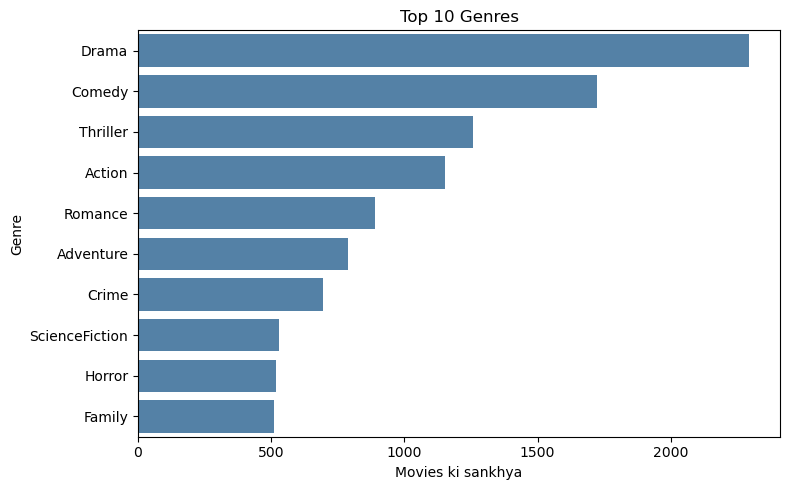

In [131]:
genre_counts = df['genres_clean'].str.split().explode().value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=genre_counts.values, y=genre_counts.index, color='steelblue')
plt.title('Top 10 Genres')
plt.xlabel('Movies ki sankhya')
plt.ylabel('Genre')
plt.tight_layout()
plt.savefig('chart_genres.png', dpi=150)
plt.show()

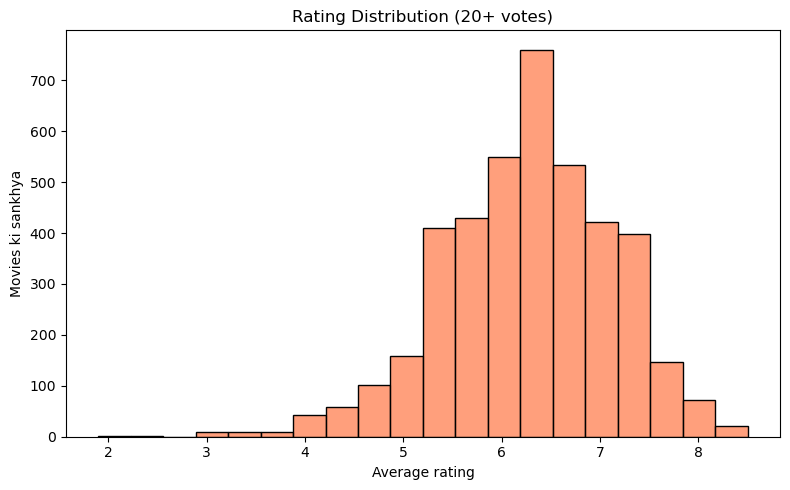

In [132]:
plt.figure(figsize=(8, 5))
sns.histplot(df[df['vote_count'] >= 20]['vote_average'], bins=20, color='coral')
plt.title('Rating Distribution (20+ votes)')
plt.xlabel('Average rating')
plt.ylabel('Movies ki sankhya')
plt.tight_layout()
plt.savefig('chart_ratings.png', dpi=150)
plt.show()

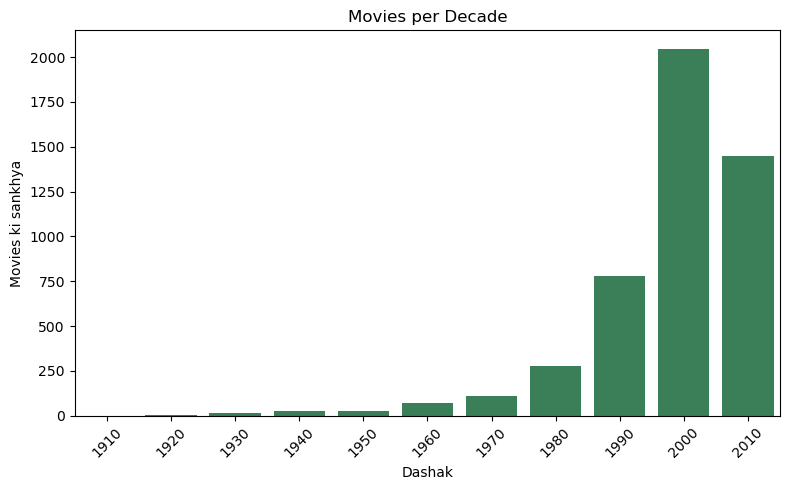

In [133]:
decade = (df['release_year'] // 10 * 10).value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=decade.index.astype(int), y=decade.values, color='seagreen')
plt.title('Movies per Decade')
plt.xlabel('Dashak')
plt.ylabel('Movies ki sankhya')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('chart_decades.png', dpi=150)
plt.show()

In [134]:
import scipy.sparse as sp

sp.save_npz('tfidf_matrix.npz', tfidf_matrix)
df[['title', 'genres', 'director', 'vote_average', 'vote_count']].to_csv('movies_clean.csv', index=False)

import os
print(os.path.getsize('tfidf_matrix.npz') / 1e6, "MB")

1.920038 MB
